> **仓库整理提示｜2026-11-23**：本篇来自已保存的中文学习版，不保证包含个人电脑上的后续修改。本次未重新执行真实数据；保留输出仅作示例，不是本次复现记录。
>
> 先阅读 [运行指南](../../guides/setup.md) 和 [版本来源](SOURCES.md)。从前往后执行，辅助函数必须先定义再调用。下面开始原中文学习版正文。


# **教程 7：DAS 流式处理、实时回放与在线震相拾取**

> **中文版 v3｜2026-11-19**。基于 xdas-dev/tutorials 的 `07_streaming_and_real_time.ipynb` 汉化，原项目采用 GPL-3.0。保留原算法顺序与原示例输出；补充说明不代表原作者观点。
>
> **稚方Xttus × ChatGPT（Codex）｜共同整理，边学边完善**。

## **本篇的目的：从“处理一份文件”走向“数据到达就处理”**

你已经能打开 DAS 记录、配置 Atom、分块计算和运行模型。本篇回答：如果数据不停到达，如何接收每一块，保持滤波／模型状态，把结果持续交付出去，并在适当时刻结束？

这里用智利海底通信光纤记录中的一个事件片段，**模拟**实时采集。输入仍是时间—沿纤距离数组；本篇没有搭建 DAS 光路，也没有接入真实仪器，不会重新执行教程六的关联定位。

| 章节 | 学习任务 | 得到什么 |
| --- | --- | --- |
| 1. 回放准备 | 把已有事件分成 16 个包，模拟逐包到达 | `packets`、`tape`、`acquire` |
| 2. 目录输入 | 接收已写好的文件，执行重采样／高通／绝对值 | `live` 与离线 `offline` 对照 |
| 3. 缺包 | 跳过一包，观察时间缺口与状态重置 | `patchy` 与样本数对照 |
| 4. 网络输入输出 | 发布原波形、处理、接收处理结果 | `raw`、`processed`、`seen` |
| 5. 在线拾取 | 跨包积累模型窗口，预测 P/S 并写表 | `picks`、CSV 与叠加图 |
| 6. 部署边界 | 理解停止、延迟、队列、存储和异常恢复 | 从教学演示到工程部署的检查项 |

## **运行前：哪些文件从哪里来？**

| 路径／资源 | 来源与准备步骤 | 本篇用途 |
| --- | --- | --- |
| `outputs/event.nc` | **教程二**中选取事件片段并保存为 NetCDF 的步骤；不是教程六的输出 | 唯一必需的本地波形输入 |
| `PhaseNet` 的 `diting` 权重 | 教程三／五使用的预训练模型；第 5 节加载时无缓存可能联网下载 | 在线拾取；前面的滤波与传输实验不需要它 |
| `outputs/replay/` | 本篇第 1 节生成 | 提前准备的完整回放文件 |
| `outputs/incoming/`、`outputs/incoming_lossy/` | 本篇第 2、3 节生成 | 模拟连续／缺包输入 |
| `outputs/live_picks.csv` | 本篇第 5 节生成 | 在线 P/S 候选到时，不是地震目录 |

**不需要** `station_picks.csv`、`stations.xml`、`catalog.csv` 或 `marot2014.csv`。缺少 `event.nc` 应回到教程二的保存步骤，不要为了本篇重跑 EarthScope 或 GaMMA。

把 Notebook 放在教程项目根目录，使用项目环境内核，按顺序运行。路径均相对项目根目录，不绑定个人盘符。`xd.open(...).load()` 会把片段装入内存；本例是有限小片段，不建议将它直接替换成几小时全通道记录。后续多个数组、列表和模型还会增加内存占用。

## **与原教程不同的兼容与保护措施**

- 开头检查本篇所需 API，不仅凭版本号判断兼容。缺少 `xd.watch`、`until` 或订阅握手接口时，先核对项目环境；不静默跳过实验，也不自动升级依赖。
- 原例删除旧目录和 CSV；中文版先将旧输出**改名备份**，不删除。改名本身不是复制，但新一轮输出会额外占空间。请先结束旧线程再重跑，不要在目录正被使用时更名。
- Windows／macOS 的目录回放使用本篇辅助完成标记；Linux 保留原 `xd.watch` 路径。适配器定义在前、调用在后，并明确不等于通用仪器驱动。
- 有限回放设置 `until`，但它不是墙钟超时。后台线程、端口、订阅握手异常时，仍可能需要中断当前单元格并重启内核清理。

## **阅读约定**

原示例输出与最后一张 PNG 已保留，供离线阅读；它们不表示你的电脑已运行。运行代码会替换对应输出，本机耗时、包数与拾取数量以实际输入为准。`assert` 通过时通常无输出。中文导读与补充解释均为新增；下面明确标记原教程正文开始。

---
# **原教程正文开始**

英文原题：*Streaming and real time*。以下保留原教程的实验顺序，穿插明确标注的中文说明与兼容代码。
---

# **流式处理与实时分析**

前面的教程处理的是已经录好的有限数据：它有起点和终点，我们可以先检查、再按需要分块。实时采集中，采集仪不会等处理程序准备好才继续测量，新数据仍会不断到来。

处理步骤往往可以复用，变化主要在两端：**数据从哪里来、处理结果写到哪里**，以及如何停止。这里复用的是教程三一类的波形处理与拾取思路，**不是把教程六的 GaMMA 定位流程直接搬过来**。

本篇使用已有记录模拟仪器，没有连接真实采集仪。先验证同一流水线在回放与离线条件下的结果，再讨论真正部署还需要补什么。

In [1]:
import shutil
import threading
import time
from pathlib import Path

import numpy as np

import xdas as xd

### **运行前检查（中文版补充）**

先检查工作目录、教程二生成的输入及实时接口。项目依赖声明的版本下限不代表所有较旧安装都包含本篇接口，以检查结果为准。后面要使用的辅助函数在下一格完整定义；如果此格报错，请先解决，不要跳到后面继续。

In [ ]:
import inspect
import platform

print("当前工作目录：", Path.cwd())
print("XDAS 版本：", getattr(xd, "__version__", "未知"))
print("XDAS 路径：", xd.__file__)
input_path = Path("outputs/event.nc")
if not input_path.is_file():
    raise FileNotFoundError(
        "缺少 outputs/event.nc。请回到教程二‘选取事件片段并保存’步骤；"
        "若文件已有，先确认 Notebook 的工作目录是教程项目根目录。"
    )
try:
    from xdas.processing import ZMQPublisher, ZMQSubscriber
    if not callable(getattr(xd, "watch", None)):
        raise AttributeError("xd.watch")
    if not hasattr(ZMQPublisher, "wait_for_subscribers"):
        raise AttributeError("ZMQPublisher.wait_for_subscribers")
    if not hasattr(ZMQSubscriber, "wait_until_subscribed"):
        raise AttributeError("ZMQSubscriber.wait_until_subscribed")
    probe = xd.resample(..., interval=250, snap=True, dim="distance")
    params = inspect.signature(probe.process).parameters
    if "until" not in params and not any(p.kind == p.VAR_KEYWORD for p in params.values()):
        raise AttributeError("Atom.process(..., until=...)")
except (ImportError, AttributeError, TypeError, ValueError) as exc:
    raise RuntimeError(
        "当前 XDAS 缺少本篇使用的接口。请确认使用教程项目环境，并核对与原教程匹配的版本；"
        "不要在正在运行的内核中混用不同环境。原始问题：" + str(exc)
    ) from exc
print("已找到教程二的输入，本篇基础接口检查通过。")
print("文件回放模式：", "Linux 关闭事件监听" if platform.system() == "Linux" else "完成标记适配")

### **辅助函数：输出备份与跨平台回放（中文版补充）**

这格只定义函数和类，不开始采集，也不删除数据。`backup_existing` 为备份改名；`ReadyFileSource` 实现“完整文件→数组块”的适配协议；`watch_replay_directory` 根据系统选用它或原 `xd.watch`。完成标记回放每次最多等待一个新包 60 秒，避免演示永久等待；这不是为真实采集设置的通用超时。

In [ ]:
from datetime import datetime


def backup_existing(path):
    """把本篇指定的旧输出改名备份；不删除、不复制。"""
    path = Path(path)
    if path.exists():
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        backup = path.with_name(path.name + ".backup_" + stamp)
        path.rename(backup)
        print("旧输出已改名：", backup)
    return path


def prepare_output_directory(path):
    path = backup_existing(path)
    path.mkdir(parents=True, exist_ok=False)
    return path


class ReadyFileSource:
    """仅用于本篇回放：看到 .nc.ready 后读取对应的完整 .nc。"""

    chunk_dim = "time"
    unbounded = True

    def __init__(self, directory, timeout=60.0, poll_interval=0.05):
        self.directory = Path(directory)
        self.timeout = timeout
        self.poll_interval = poll_interval
        self.seen = set()
        self.stopped = threading.Event()

    def __iter__(self):
        return self

    def __next__(self):
        deadline = time.monotonic() + self.timeout
        while not self.stopped.is_set():
            for marker in sorted(self.directory.glob("*.nc.ready")):
                if marker.name not in self.seen:
                    path = marker.with_suffix("")
                    chunk = xd.open(path).load()
                    self.seen.add(marker.name)
                    return chunk
            if time.monotonic() >= deadline:
                raise TimeoutError(
                    f"{self.directory} 在 {self.timeout:g} 秒内没有新的完整回放包。"
                    "请检查 acquire 线程、完成标记和目标时间；until 不是超时。"
                )
            self.stopped.wait(self.poll_interval)
        raise StopIteration

    def stop(self):
        self.stopped.set()


def watch_replay_directory(directory):
    """Linux 用原监听；其他系统用本篇显式完成标记协议。"""
    if platform.system() == "Linux":
        return xd.watch(directory)
    return ReadyFileSource(directory)

## **1. 用已有记录准备回放数据包**

没有真实仪器，就把教程二保存的 `outputs/event.nc` 作为回放素材。下一格先读入内存，再沿默认的第一维分成 **16 份**。本例第一维为 `time`，共 4000 个样本，采样间隔 0.016 秒，因此每份 250 个时间样本，对应约 4 秒记录。

**`xd.split(da, 16)` 中的 16 是份数，不是 16 秒，也不是每份 16 个样本。**若换用其他长度或维度顺序，不能继续照搬“每包 4 秒”的解释。后面按原例把数据包写入 `outputs/replay/`，这只是预先准备的回放素材目录，不是实时输入目录。

`packets[0]` 显示的是原始片段：横跨所有距离位置，时间只有第一小段。`distance` 是沿纤距离（米），数值不是光纤位移；附带经纬度缺失不会妨碍本篇按距离与时间处理。

In [2]:
da = xd.open("outputs/event.nc").load()
packets = xd.split(da, 16)
packets[0]

<xdas.DataArray (time: 250, distance: 10000)>
[[ 10121  10100    -42 ...  -1304   1441  -2011]
 [-16538 -16551    -35 ...  -1147  -4321   1827]
 [ 20025  20039     22 ...   1903  -1450  -2908]
 ...
 [-11057 -11142    -65 ...    761   4018   1492]
 [ 15091  15061    -52 ...   -145   1965   2862]
 [-11356 -11336     -1 ...     57  -1184  -4165]]
Coordinates:
  * distance (distance): 0.000 to 153179.709
  * time (time): 2023-11-03T12:26:40.008 to 2023-11-03T12:26:43.992
    latitude (distance): [nan ... nan]
    longitude (distance): [nan ... nan]

### **检查包长与内存（中文版补充）**

下面核对实际时间采样间隔、包内时间样本数与原数组大小。第一包首末时间相差约 3.984 秒，是因为 250 个样本只有 249 个间隔；按 `样本数 × 采样间隔` 计算的记录时长为 4 秒。这个区别不是缺失了一个样本。

In [ ]:
if da.dims[0] != "time":
    raise ValueError("本篇 xd.split(da, 16) 默认沿第一维切分，请先确认第一维是 time。")
dt = np.asarray(da["time"].values[1] - da["time"].values[0]) / np.timedelta64(1, "s")
print("时间采样间隔（秒）：", float(dt))
print("每包时间样本数：", [p.sizes["time"] for p in packets])
print("第一包名义记录时长（秒）：", packets[0].sizes["time"] * float(dt))
print("原数组数值区大小（MiB，不含其他对象）：", da.values.nbytes / 2**20)

In [3]:
replay = prepare_output_directory("outputs/replay")

for index, packet in enumerate(packets):
    packet.to_netcdf(replay / f"{index:03d}.nc")

tape = sorted(replay.glob("*.nc"))
len(tape)

16

### **1.1 用后台线程模拟采集仪**

下方只定义函数，**尚未开始复制**。以后调用 `acquire(incoming)` 才启动线程：每隔 `delay` 秒，把一个完整数据文件复制到输入目录，然后继续下一份。

| 参数或语句 | 含义 |
| --- | --- |
| `delay=0.25` | 每发送一包之前，按电脑时钟等待 0.25 秒 |
| 每包约 4 秒数据 | 包内数据时间坐标覆盖的记录长度，不是发送等待时长 |
| `skip=(8,)` | 跳过从 0 编号的第 8 包，即第 9 个文件 `008.nc` |
| `thread.start()` | 启动模拟采集线程，主线程可以同时处理 |
| `return thread` | 返回线程对象，后面用它等待采集完成 |

本例是**加速回放**：约每 0.25 秒送入 4 秒记录，名义上约为 16 倍记录速度，还要加上复制耗时。它验证的是流式处理机制，不是严格按原速的实时仪器，也不是稳定性或性能基准。

In [4]:
def acquire(into, delay=0.25, skip=()):
    """模拟采集：逐包复制；非 Linux 在复制完成后写入标记。"""
    into = Path(into)

    def run():
        for index, path in enumerate(tape):
            if index in skip:
                continue
            time.sleep(delay)
            destination = into / path.name
            shutil.copyfile(path, destination)
            if platform.system() != "Linux":
                destination.with_name(destination.name + ".ready").touch()

    thread = threading.Thread(target=run)
    thread.start()
    return thread

## **2. 监听目录：文件到达后就处理**

一种常见采集方式是让仪器持续把文件写入目录。原教程用 `xd.watch(path)` 把新文件转换成逐块产生 `DataArray` 的数据源。**在原实现中，触发点是文件关闭事件，不是泛指文件“出现在目录里”。**

这是一个无界数据源：当前没有新包时会等待，不会因为暂时无文件就宣告结束。`process` 因而不显示已知总量。把一个普通目录路径直接传入 `process`，通常只是读取已有文件，**不等于持续监听**。

### **2.1 先说明三个处理步骤**

| 代码步骤 | 输入→操作→输出 | 为什么这样处理 |
| --- | --- | --- |
| `xd.resample(..., interval=250, snap=True, dim="distance")` | 波形数组→沿距离轴低通重采样→更少距离通道的波形 | 减少后续计算；会舍弃部分细尺度空间变化 |
| `xd.filter(..., (1.0, None), ftype="iir", order=4, dim="time")` | 波形→沿时间轴四阶 IIR 高通→抑制约 1 Hz 以下的缓慢分量 | 让较快变化更显眼；不是去掉全部噪声，也不是识别地震 |
| `np.abs` | 有正负号的波形→逐元素取绝对值→非负幅度 | 便于幅度显示；丢失符号，不等于计算能量 |

`interval=250` 使用原距离单位，即目标约 250 米。`snap=True` 要求输出落在原采样网格上，以最接近目标的整数抽取因子实现，**实际间距不保证恰好 250 米**；这里也不是每 250 个通道取一个。默认 FIR 低通重采样不同于直接删去中间通道。以输出坐标核对实际间距。

`...` 在这两个 XDAS 函数的输入位置表示先配置 Atom，等待后续数据；`>>` 连接处理单元；`pipeline` 只是保存此时这套步骤的变量名，不是固定算法名。原始数据传入 `.process(...)` 后才真正处理。

In [5]:
pipeline = (
    xd.resample(..., interval=250, snap=True, dim="distance")
    >> xd.filter(..., (1.0, None), ftype="iir", order=4, dim="time")
    >> np.abs
)
pipeline

Sequential:
  0: Resample(interval=250, snap=True, dim='distance')
  1: Filter(freq=(1.0, None))
  2: absolute(...)

### **补充读图：四阶 IIR 是什么？什么“波”能过去？**

先对应本格代码：

```python
xd.filter(..., (1.0, None), ftype="iir", order=4, dim="time")
```

| 参数 | 含义 | 容易混淆的地方 |
| --- | --- | --- |
| `(1.0, None)` | 1 Hz 高通：抑制较慢的变化，保留较快的振荡 | 不是 1–10 Hz 带通，也不是“每秒通过一个波” |
| `ftype="iir"` | 本接口采用 Butterworth IIR，以二阶节实现 | IIR 是滤波器类型，不是一种波形；输出依赖历史输入及状态 |
| `order=4` | 四阶，影响幅频过渡的陡峭程度 | 不是只能通过四种频率、滤波四次或四秒窗口 |
| `dim="time"` | 对各个距离位置的时间序列滤波 | 这里的 1 Hz 是时间频率，不是距离方向的波数 |

**能否通过，主要取决于频率，不取决于它被叫作地震波、噪声、P 波还是 S 波。**真实地震波和噪声都可能覆盖多个频率：低频地震成分也可能被削弱，高频噪声也能通过。因而这个滤波器不是“自动去噪／识别地震”的开关。

#### **图 A：不是 1 Hz 以下全消失、以上完全不变**

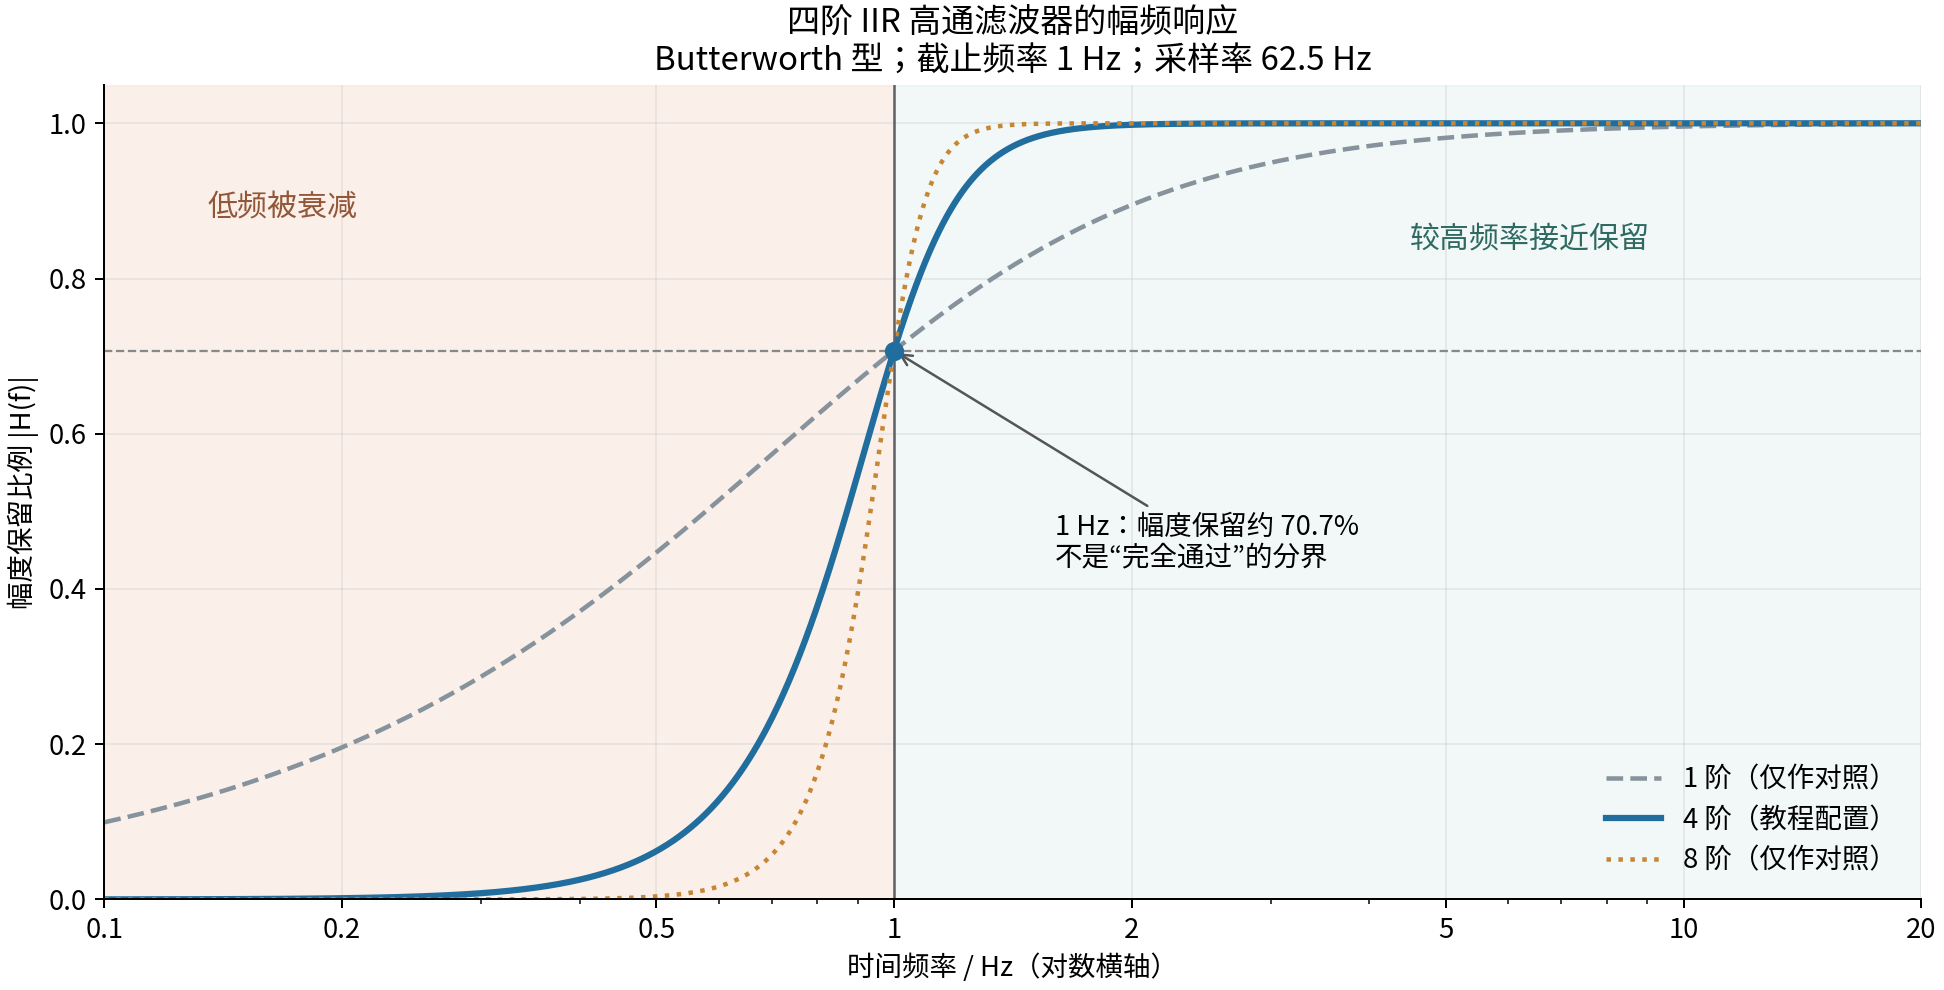

横轴是时间频率，采用对数刻度；纵轴是幅度保留比例，1 表示输入正弦波的稳态幅度近似保留，0 表示该频率被抑制。**这不是随时间变化的波形图。**蓝色实线对应教程的四阶配置，一阶和八阶仅用于理解阶数，不会修改当前流水线。

在相同截止频率下，阶数越高，通常过渡越陡；但不能据此说阶数越高越好，还要考虑相位、瞬态、数值稳定性及任务需要。**本例 1 Hz 的幅度仍剩约 70.7%（−3 dB），不是全部通过，也不是只剩 50% 幅度。**对正弦分量而言，对应的功率比例约为 50%。

以下数值由四阶数字 Butterworth 高通计算，采样率设为本教程原片段的 62.5 Hz，表示稳态幅度比例，不是准确率或能量百分比：

| 输入正弦分量的频率 | 滤波后幅度 / 滤波前幅度 |
| --- | --- |
| 0.1 Hz | 0.010% |
| 0.2 Hz | 0.159% |
| 0.5 Hz | 6.222% |
| 1 Hz | 70.711% |
| 2 Hz | 99.809% |
| 5 Hz | 100.000% |
| 12 Hz | 100.000% |

表中数值保留三位小数；显示为 100.000% 是四舍五入的结果，不表示严格完全没有衰减。

直观地说，0.2 Hz 每 5 秒振荡一次，会被强烈削弱；5 Hz 每秒振荡 5 次，会较好保留。恒定偏置属于直流（0 Hz），稳态下也会被抑制。`None` 表示这里没有额外设置高频截止，不表示数字采样数据能保留无限高频；实际频率范围仍受采样率、前级处理和仪器带宽限制。

#### **图 B：滤波后的波形，以及取绝对值后的波形**

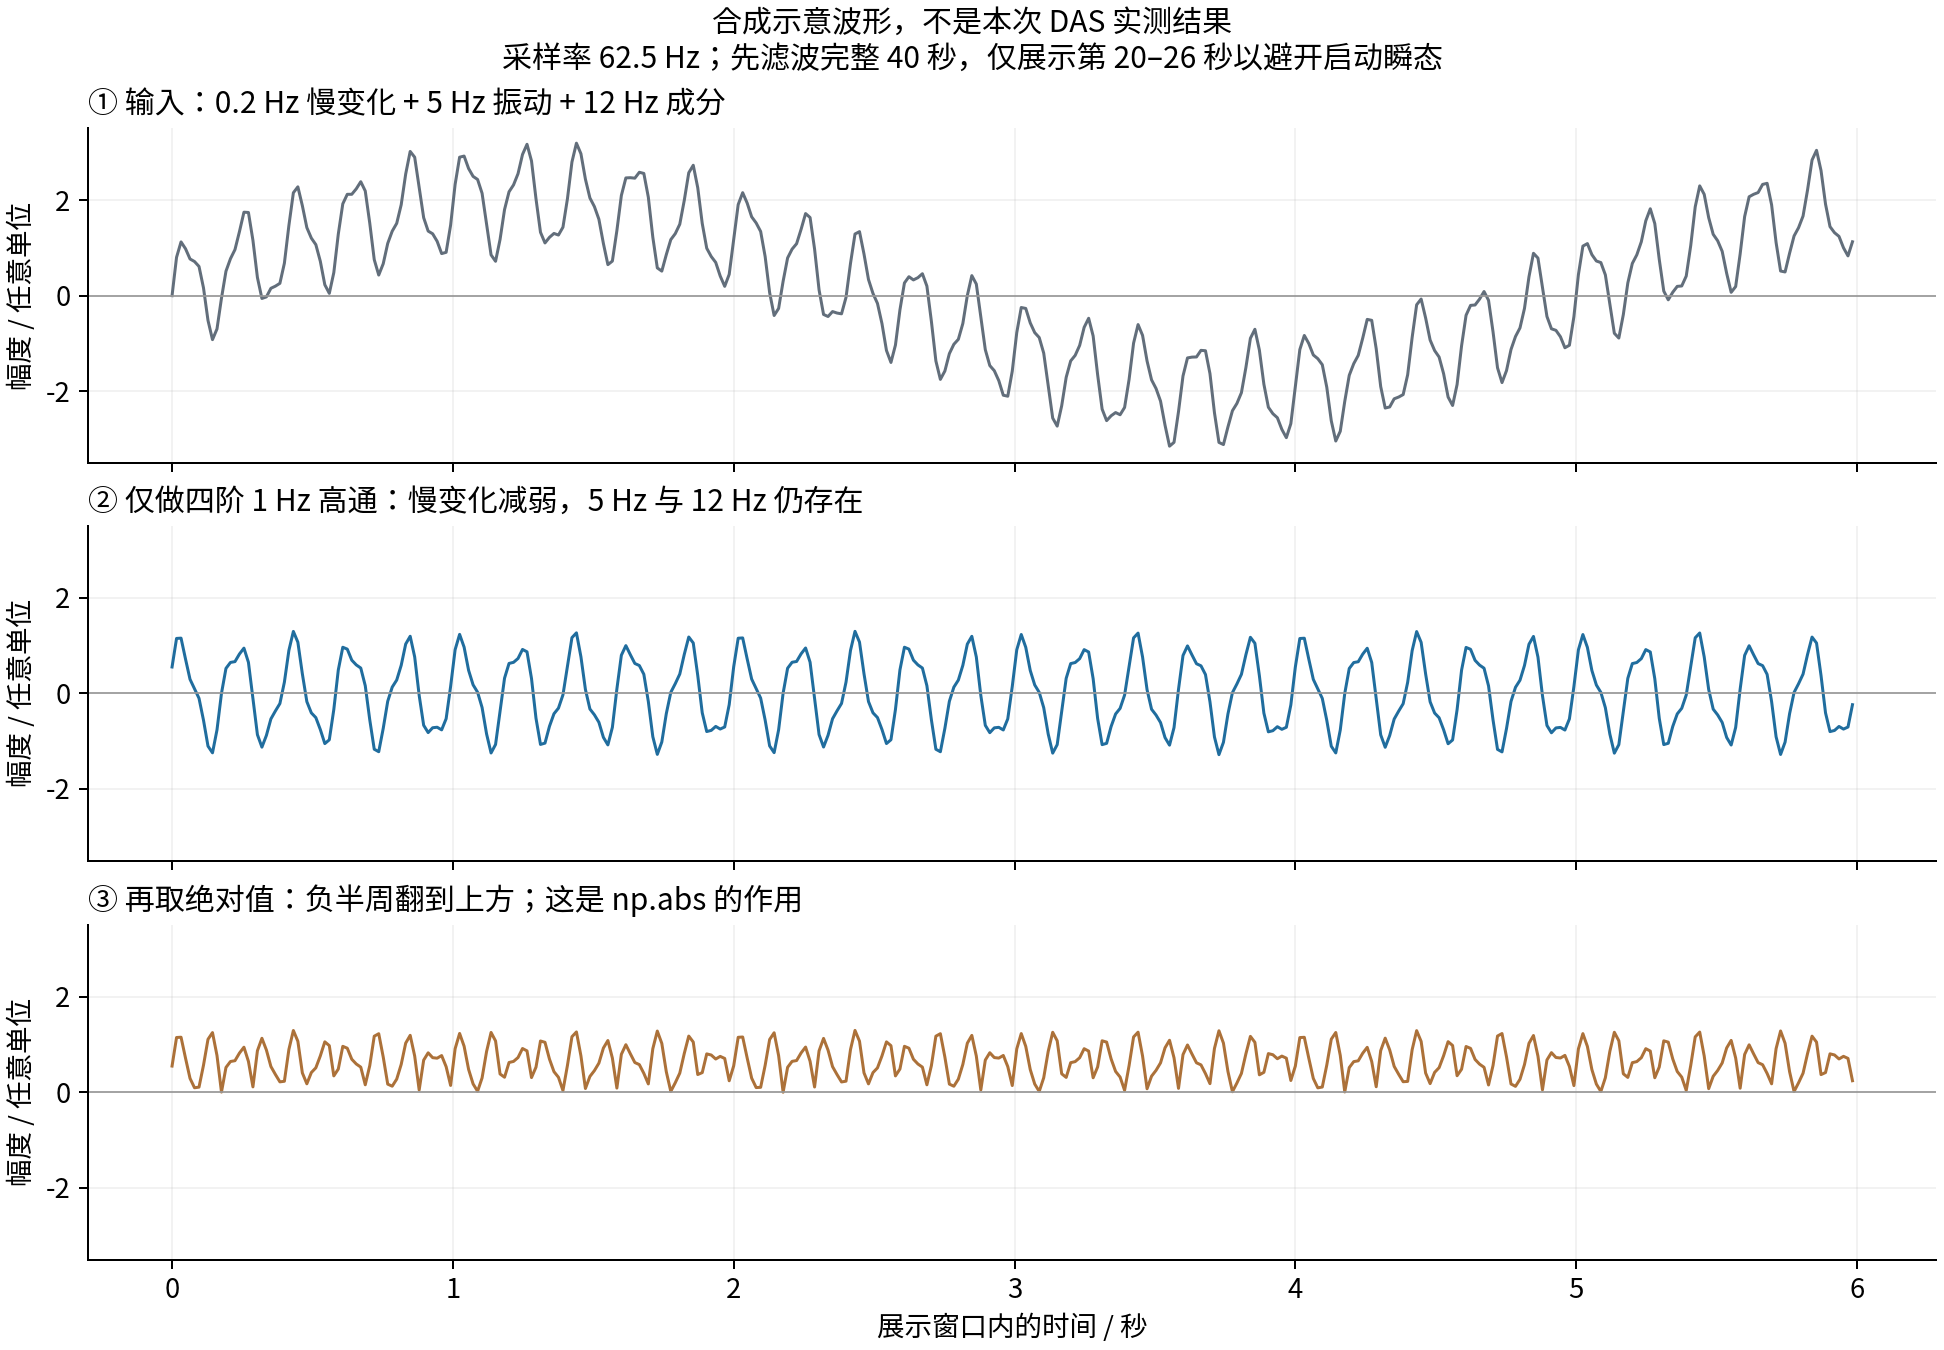

这张是**合成教学示意图，不是你本次运行得到的 DAS 波形**。三行采用同一时间范围、同一纵轴尺度：

1. **第一行**人为叠加 0.2 Hz 的慢变化、5 Hz 振动和较弱的 12 Hz 成分，所以快速波形骑在缓慢起伏的背景上。
2. **第二行**只做本例的四阶 1 Hz 高通。缓慢背景大幅减弱，5 Hz 和 12 Hz 都还在，波形仍有正负；它不会自动变成一条纯正弦波。因果 IIR 还会改变各频率的相位，不能假定输出峰值与输入峰值处处对齐，或简单等价于固定延迟。
3. **第三行**对第二行做 `np.abs`。负值被翻成正值，所以全部非负；这是**取绝对值**造成的，不是高通本身造成的。取绝对值是非线性操作，会改变频谱，不能再用图 A 直接解释第三行的全部频率成分，也不能把它称作平方能量。

图中先处理完整 40 秒，只展示第 20–26 秒以减少启动瞬态干扰。真实记录的起点、缺口后状态重置附近都可能出现瞬态；后面的缺包实验正会用到这个概念。

**与后面的时距图对应：**每个距离位置都经历类似的时间滤波，再把各通道拼成时距图。后面 `live`／`offline` 的颜色显示的是重采样、高通、取绝对值后的非负幅度，既不是原始有符号波形，也不是 P/S 概率。第 5 节另建的 `detector` 并没有直接接入本格的高通与 `np.abs`，不要将这段展示流程误认为模型输入必经的预处理。

**依据与示意范围：**[XDAS Filter 文档](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.atoms.Filter.html)明确本接口的高通参数、Butterworth IIR 与因果实现；[SciPy butter](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html)解释 −3 dB 截止点；示意图使用 `butter(4, 1.0, btype="highpass", fs=62.5, output="sos")`、`sosfreqz` 和因果 `sosfilt` 计算，不使用双向零相位滤波。本图只解释时间高通，不额外模拟前一阶段的空间重采样。


### **2.2 何时停止？先理解 until，再执行下一格**

`until=da["time"].values[-1]` 取事件片段最后一个**数据时间坐标**作为终点。处理到包含该时刻的包时，将其截到该位置并正常收尾；本例最后一包本来就到这个时刻。

它不是“运行多少秒”，也不是“电脑现在的时间”。即使数据采于 2023 年，今天回放仍应使用记录里的时间。若流再也不送来目标时刻或更晚的包，`until` 自己不会唤醒正在等待的读取器。不要把末包也跳过再期待它自动结束。

终端中的 Ctrl-C 或 Jupyter 的“中断内核”可尝试结束当前运行，原实现对无界流会正常收尾；若底层等待或后台线程未退出，可能仍需重启内核。不要关闭窗口后以为所有线程都已安全清理。

In [6]:
incoming = prepare_output_directory("outputs/incoming")

source = watch_replay_directory(incoming)  # 先准备接收，再开始回放
instrument = acquire(incoming)

live = pipeline.process(source, until=da["time"].values[-1])
instrument.join()
live

76.3MB [00:04, 19.3MB/s, read=73.2%, proc=26.8%, write=0.0%]


<xdas.DataArray (time: 4000, distance: 625)>
[[1088.575273   24.054773   11.868901 ...  972.135786  601.368745
    36.221027]
 [2103.140201  123.718653   39.457832 ...   76.833913  401.824247
    44.919561]
 [2432.215477  118.19305    66.782645 ...  516.341048  126.928268
   247.977904]
 ...
 [1143.766793   27.402197   11.012397 ...  162.529147  394.37716
   387.786622]
 [1301.565643   50.657764   21.160681 ...   81.554012   82.263968
   135.791466]
 [1360.213959   73.090843   13.31417  ...  309.942321  193.690964
   130.474723]]
Coordinates:
  * distance (distance): 0.000 to 152949.917
    latitude (distance): [nan ... nan]
    longitude (distance): [nan ... nan]
  * time (time): 2023-11-03T12:26:40.008 to 2023-11-03T12:27:43.992

### **2.3 运行结果与进度信息怎样读？**

原示例的 `live` 为 `(time: 4000, distance: 625)`：时间样本仍为 4000，距离通道从 10000 减至 625，数值经过高通和取绝对值。这些尺寸来自原例，不是所有输入的固定结果。

进度中的 `76.3MB` 是按输入数组字节数累计的处理量，不是文件数或地震数量。`read / proc / write` 是各阶段的耗时占比，**不是 CPU 占用率**：

- `read` 包含等待下一个数据块，所以占比高可能是在等模拟仪器，不一定是磁盘慢。
- `proc` 是处理阶段耗时；`write` 是交付给输出端的耗时，内存输出可能很小。
- `proc` 长期接近 100% 是处理余量不足的警讯，但不能只凭百分比断定必然积压。还应看平均处理一包是否慢于包到达间隔、队列长度、端到端延迟及峰值负载。

下面的离线对照把相同 `da` 一次送入同一 `pipeline`。`assert` 通过时没有输出，这是正常现象。`array_equal(..., equal_nan=True)` 检查数组值逐元素严格相同，并允许对应位置的 NaN 相同；这行本身没有比较坐标或检验科学解释是否正确。

In [7]:
offline = pipeline(da)
assert np.array_equal(live.values, offline.values, equal_nan=True)

### **2.4 为什么不能“随便把文件放进去”？**

原 `xd.watch` 实现响应文件关闭事件。把已存在的文件移动到目录里，不一定触发所需事件；直接对监听目录调用 `to_netcdf`，还可能经历多次打开／关闭，在数据尚未完整时被读入。读取异常发生在监听线程里时，主处理循环可能仍在等待。

因此原例先在 `replay` 中生成完整文件，再用 `shutil.copyfile` 复制，减少读到未写完文件的风险。**复制不是所有文件系统和真实仪器的通用完整性保证**，生产系统需要明确的文件完成协议。原实现及 Watchdog Windows 后端的差异见文末依据。

中文版在 Windows／macOS 上使用“复制完成后写 `.ready` 标记”的教学适配器：消费者只读取已有完成标记的 `.nc`。Linux 仍使用原 `xd.watch`。这套标记由本篇的 `acquire` 产生，**真实仪器不会自动遵守，不能不加适配就直接套到仪器输出目录**。不要在 Linux 的原监听目录中额外写这些标记文件。

## **3. 模拟缺一包：为什么要重置滤波状态？**

离线档案可以预先检查时间坐标；流式输入只能在后一包到来后，判断它是否紧接着前一包。下面跳过第 9 包 `008.nc`，模拟一段未到达的数据。**必须保留真实时间坐标**，不能把后面的时间向前挪来伪装连续。

In [8]:
lossy = prepare_output_directory("outputs/incoming_lossy")

source = watch_replay_directory(lossy)
instrument = acquire(lossy, skip=(8,))

patchy = pipeline.process(source, until=da["time"].values[-1])
instrument.join()

38.1MB [00:02, 19.6MB/s, read=72.9%, proc=27.1%, write=0.0%]/home/trabatto/pkgs/tutorials/.venv/lib/python3.12/site-packages/xdas/processing/core.py:309: UserWarning: realtime source has a discontinuity along 'time' at 2023-11-03T12:27:16.008000000; state is flushed and reset
  previous = _announce_realtime_seam(previous, chunk, chunk_dim)
71.5MB [00:03, 19.2MB/s, read=73.4%, proc=26.6%, write=0.0%]


### **3.1 警告说明了什么？**

原例在缺口后的首包到达时给出 `discontinuity` 警告，并说明 `state is flushed and reset`：输出已有缓冲尾部，结束旧的连续段，再为新的连续段重新初始化状态。这里不是内核崩溃，也不是自动补回丢失数据。

为什么不能继续沿用高通滤波状态？IIR 当前输出依赖历史状态，缺失区间的输入并不知道。直接衔接相当于假装前后两包连续，会引入错误假设。重置后也可能出现新的边界瞬态，不能把它直接判断为真实振动。

因此缺包结果**不等同于先对完整记录滤波、最后再删掉缺口**：后者已经利用了那段实际上没有收到的数据。

下一格原例输出 4000 和 3750 个时间样本，相差 250，正好是一个约 4 秒的数据包。它不会补零或插值恢复；时间轴仍保留缺口。这里的 `skip` 模拟上游没有发送一包，不是在证明 TCP 网络必然按这种方式丢包。

In [9]:
print(f"{live.sizes['time']} samples continuous, {patchy.sizes['time']} with the gap")

4000 samples continuous, 3750 with the gap


## **4. 通过 ZeroMQ 传输数据块**

除了文件，也可以通过网络套接字逐包传输 `DataArray`。ZeroMQ 是消息通信库，不是 Python 线程，也不是另一种滤波算法。发布端（publisher）发送，订阅端（subscriber）接收。

| 节点 | 收到什么 | 做什么 | 发往哪里 |
| --- | --- | --- | --- |
| `interrogator`：模拟采集端 | `packets` 中的回放包 | 等处理端订阅后逐包发送 | `raw` 地址 |
| 主线程：处理端 | 从 `raw` 订阅原波形 | 执行 `pipeline` | `processed` 地址 |
| `display`：接收端 | 从 `processed` 订阅结果 | 保存到 `seen` 列表 | 当前内存，不在此函数中画图 |

本例是**同一台电脑上的线程模拟**，不是已经部署到三台机器。`localhost` 表示本机；`get_free_port()` 找到暂时可用的本机端口，不是长期预留，极端情况下仍可能竞争。跨机器需要分别设计地址绑定、连接、防火墙和安全策略，不能把 `localhost` 原样搬过去。

### **4.1 为什么要等待订阅？**

发布端刚建立时，订阅关系不一定已经生效，过早发布的开头消息可能被丢弃。有限记录回放要求完整保留开头，因此由**发布端调用 `wait_for_subscribers()`**，确认已有订阅者后再发。

真实采集仪通常不能为某个订阅者暂停测量，订阅者可用 `wait_until_subscribed()` 确认自己已接入；但这不会补回它加入之前的历史数据。**等待订阅只是解决启动时序，不是全程零丢失、持久化或断线重传保证。**

In [10]:
from xdas.io import get_free_port
from xdas.processing import ZMQPublisher, ZMQSubscriber

raw = f"tcp://localhost:{get_free_port()}"
processed = f"tcp://localhost:{get_free_port()}"

In [11]:
def interrogator():
    with ZMQPublisher(raw) as publisher:
        publisher.wait_for_subscribers()  # 有限记录回放，等订阅就绪再发送开头
        for packet in packets:
            publisher.submit(packet)


seen = []


def display():
    with ZMQSubscriber(processed, timeout=60.0) as subscriber:
        for chunk in subscriber:
            seen.append(chunk)
            if len(seen) == len(packets):
                break

### **4.2 为什么传入现成的 publisher 对象？**

处理端也是发布端：它需要等 `display` 订阅，再发送第一个处理结果。若只写 `out=processed`，`.process()` 会内部创建发布器，外部难以在其开始发送前插入等待。

所以这里先 `with ZMQPublisher(processed) as publisher`，等待接收端就绪，再传入 `out=publisher`。`with` 退出时关闭这一端的通信资源；`node.join()` 是等待线程结束，**不是连接或合并数据**。

下一格才启动两条后台线程，并在主线程执行流式处理。原例 `display` 的停止条件是收到与输入包数相同的块数，这只适用于本例一包输入对应一包输出的配置；不能用于会缓存、合并或改变输出块数的任意流水线。

In [12]:
nodes = [threading.Thread(target=interrogator), threading.Thread(target=display)]
for node in nodes:
    node.start()

with ZMQPublisher(processed) as publisher:
    publisher.wait_for_subscribers()  # 确认 display 已订阅处理结果
    result = pipeline.process(raw, out=publisher, until=da["time"].values[-1])

for node in nodes:
    node.join()

print(f"{len(seen)} chunks arrived at the display, and process returned {result}")

76.3MB [00:03, 24.2MB/s, read=46.8%, proc=33.6%, write=19.6%]


16 chunks arrived at the display, and process returned None


### **4.3 返回 None，不是没有处理结果**

原例显示 `16 chunks arrived ... process returned None`。这里 `.process(..., out=publisher)` 把结果逐包发往网络，而 `ZMQPublisher.result()` 不聚合出一份数组，因此返回 `None`。

接收端已经把数据放进 `seen`。下面 `xd.concat(seen)` 才把收到的块合成数组，再与离线结果逐元素比较。`seen` 和 `live` 都是本篇有限测试的内存输出方式，真正无限运行不能让它们一直增长。

In [13]:
assert np.array_equal(xd.concat(seen).values, offline.values, equal_nan=True)

### **真实仪器协议与本篇协议不同**

本篇 `xdas.processing.ZMQSubscriber` 接收的是 XDAS 发布器序列化的数组消息。真实仪器即使也使用 ZeroMQ，消息头与数据格式也可能不同。`xdas.io.asn.ZMQSubscriber` 针对 ASN OptoDAS 协议解码，向下游提供相同形式的 `DataArray` 块；不能因此认为任意仪器都可用同一个订阅器。

## **5. 流式震相拾取：数据来了之后，预测在哪里执行？**

现在另建变量 `detector`，它的步骤是“约 500 米的距离重采样 → PhaseNet 拾取”。**它没有连接前面 `pipeline` 中的 1 Hz 高通和取绝对值**。模型自己的重采样、归一化、分量适配等由 `xd.pick` 与权重配置处理；不要把展示用的绝对值幅度数组误当作这里的模型输入。

PhaseNet 不能仅凭任意一个 4 秒小包立即完成整段预测。拾取单元会跨包保存波形上下文、按模型窗口推理，合并重叠输出，再依据阈值形成到时记录。需要多久上下文，取决于权重的 `in_samples / sampling_rate`，不是所有 PhaseNet 模型都固定一分钟。

| 代码位置 | 此时发生什么 |
| --- | --- |
| `PhaseNet.from_pretrained("diting")` | 加载预训练权重，不是训练，也尚未预测本篇数据；无缓存时可能联网下载 |
| `detector = ... >> xd.pick(..., model, ...)` | 配置重采样、模型和 P/S 触发阈值，尚未输入实际波形 |
| 后面的 `detector.process(raw, out=..., until=...)` | 从网络取包，跨包积累上下文，真正运行模型推理与触发，并逐批写 CSV |
| `whole = detector(da)` | 另外对完整数组执行一次离线预测，作为对照 |

`thresh={"P": 0.3, "S": 0.3}` 是模型输出分数的触发阈值，不代表结果正确率为 30%，也不是波形振幅阈值。DAS 的单通道信号并不是真正的三分量地震计，接口的模型输入适配不等于新增独立观测分量。

在线不等于零延迟：采集打包、传输、模型窗口、计算与写盘都会产生延迟。流停止时 `.process` 的正常收尾还会释放可用的缓冲输出；完整回放结束后的结果，不能直接当作每一条拾取的在线发布延迟。

In [14]:
from seisbench.models import PhaseNet

model = PhaseNet.from_pretrained("diting")

detector = xd.resample(..., interval=500, snap=True, dim="distance") >> xd.pick(
    ..., model, thresh={"P": 0.3, "S": 0.3}, device="cpu", dim="time"
)

### **核对实际模型窗口（中文版补充）**

模型窗口由权重参数决定。下面只读取已加载模型的属性，不额外预测；用它理解为什么需要跨包缓存，而不是把 4 秒包直接当成一个独立模型窗口。窗口长度不是最终完整的端到端延迟。

In [ ]:
print("模型采样率（Hz）：", model.sampling_rate)
print("模型输入窗口样本数：", model.in_samples)
print("模型输入窗口时长（秒）：", model.in_samples / model.sampling_rate)

### **准备输出 CSV（中文版补充）**

原教程用 `%rm -f` 删除旧文件，不适合通用 Windows Notebook。下面改为：旧 `outputs/live_picks.csv` 如存在就改名备份，新运行再写入原路径。它是本篇输出，不是运行前要下载的输入。

In [15]:
picks_path = backup_existing("outputs/live_picks.csv")
picks_path.parent.mkdir(parents=True, exist_ok=True)

In [16]:
instrument = threading.Thread(target=interrogator)
instrument.start()

picks = detector.process(raw, out="outputs/live_picks.csv", until=da["time"].values[-1])
instrument.join()

len(picks)

76.3MB [00:04, 16.1MB/s, read=25.7%, proc=74.3%, write=0.0%]


362

### **5.1 362 表示什么？离线对照证明了什么？**

原示例 `len(picks)` 为 **362 条候选到时记录**，不是 362 个地震，也不一定对应 362 个通道。同一通道可能提供 P、S 或其他重复候选。CSV 是表格，随模型产生结果逐批写入，不保证每来一个 4 秒包都立刻新增一行。

下面重新执行 `whole = detector(da)`，会再次运行模型，可能需要一些时间。原代码只检查 `len(picks) == len(whole)`，**仅证明两张表行数相同**；它没有逐条核对通道、震相、到时和分数，因此不能把这个断言说成“全部拾取记录已经完全一致”。这与前面的数组逐元素比较强度不同。

若要严格核验，需要先对齐并排序 ID／距离、震相与时间，再比较每条到时和分数，并根据模型数值误差规定容差；还需单独研究块边界、缺口和流尾。断言通过不代表拾取物理上都正确，仍要回看波形或使用人工标注。

In [17]:
whole = detector(da)
assert len(picks) == len(whole)

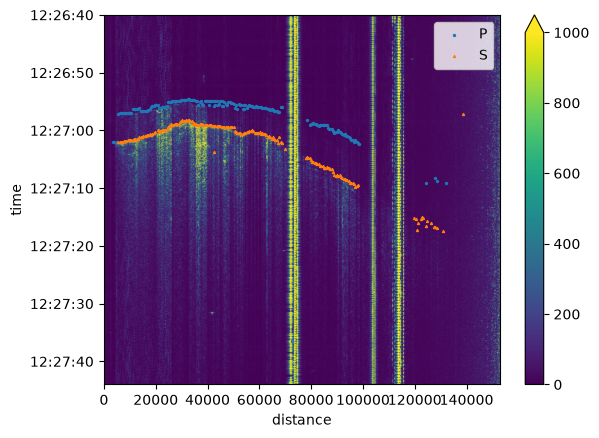

In [18]:
import matplotlib.pyplot as plt

offline.plot(yincrease=False, vmin=0, vmax=1e3, interpolation="antialiased")

for phase, marker in [("P", "o"), ("S", "^")]:
    sub = picks[picks["phase"] == phase]
    plt.scatter(sub["distance"], sub["time"], s=2, marker=marker, label=phase)

plt.legend()
plt.show()

### **5.2 最后一张图：背景和 P/S 标记分别是什么？**

**先看坐标。**横轴 `distance` 是沿纤距离，原例约 0～153000 米；纵轴是记录时间，`yincrease=False` 让较早时间在上、较晚时间在下。不是距离随时间向下移动，也不是震源深度图。

| 图中元素 | 数据来源与含义 | 不能据此直接认定 |
| --- | --- | --- |
| 背景颜色 | `offline`：约 250 米距离重采样＋1 Hz 时间高通＋绝对值 | 不是原始有符号应变率，也不是 P/S 概率或能量 |
| 色标 0～1000 | 处理后非负幅度；`vmax=1e3` 以上颜色饱和，不能分辨更大的数值 | 亮点不一定是地震，色标数字不是发生概率 |
| 蓝色小圆点 P | `picks` 中预测为 P 的候选到时 | 不是人工标注的真实 P 波，也不是震中位置 |
| 橙色小三角 S | `picks` 中预测为 S 的候选到时 | 不是所有 S 都真实，也不是经过 GaMMA 确认的同一事件 |

背景的 `offline` 与目录监听得到的 `live` 已在前面比较过数组值。这里为方便展示使用 `offline`，**不是实时刷新的动画**。标记来自在线 `detector.process`；检测器的距离目标间距约 500 米，且没有显式接入背景所用的高通／绝对值流程。因此叠加在同一坐标上，不代表两条流程用了完全相同的输入预处理。

**原示例能观察到：**较连续的 P 候选大致在 12:26:55～12:27:03，S 候选较晚，主要段约在 12:26:59～12:27:11；更远处还有较晚且离散的候选。许多点组成随距离变化的到时带，同一地震在不同位置传播时差可以产生这种形状，但本图本身没有完成事件关联或定位。

约 70 km、100 km、110 km 附近可见贯穿较长时间的竖向亮带：它们位于较固定的沿纤位置，不是“波沿时间轴垂直传播”的证据。可能涉及局部持续扰动、耦合或采集问题，需要查原波形和通道信息，不能仅凭这幅图断定原因。孤立拾取也要回看相邻通道和原始信号，不能自动当作新地震。

读图顺序建议：**先确认坐标和处理历史 → 看背景的时空结构 → 看 P/S 是否构成连贯到时带 → 记录离散点和持续亮带 → 回原波形核验**。若要比较未经滤波的图，应统一时间／距离范围与色标，并注意有符号波形与绝对值幅度不能机械共用同一种解释。

## **6. 真正部署时，还要改变什么？**

| 方面 | 本篇演示 | 实际部署要补齐 |
| --- | --- | --- |
| 输入 source | 目录回放，或本机 ZeroMQ | 仪器协议、文件完成约定、时钟与时间戳、通道和单位核对 |
| 输出 sink | 内存列表、有限 CSV、网络发布 | 分段存档、日志轮转、磁盘配额、消费确认与失败恢复 |
| 停止 stop | `until` 截到已有记录最后一个时间点 | 正常收尾、停机信号、超时、重连与任务生命周期管理 |
| 负载 | 约 64 秒记录的加速回放 | 峰值吞吐、队列长度、积压报警、端到端延迟与内存上限 |
| 完整性 | 连续回放对照、故意跳过一包 | 重复、乱序、网络中断、缺口末尾、断电恢复与数据校验 |

`out=None` 对有限测试很方便，但无限流会持续积累内存。即使写 CSV，本实现收尾时也可能读回整张表，因此长期服务还需分时段轮转；不能把本篇演示不加限制地常年运行。文件名备份也会随重复运行累积，应自行确认后清理不再需要的版本。

可以把经过验证、适合分块且正确保存状态的处理步骤复用到流式输入，但**不是任何离线算法都天然可实时化**：依赖整段未来数据、双向滤波或全局统计的步骤，要另行处理延迟与边界。

### **完成本篇后应能回答**

1. 数据包中的 4 秒，与每包等待的 0.25 秒有什么区别？
2. 为什么 `until` 已经给定，程序仍可能在没有下一包时等待？
3. 缺口后为何不能直接沿用旧滤波状态？
4. 发布端为什么等待订阅，为什么还不能承诺全程零丢失？
5. 拾取预测在哪行真正执行，最后一张图的背景和标记分别来自哪条流程？

### **依据与适用范围**

- [原教程七](https://github.com/xdas-dev/tutorials/blob/main/07_streaming_and_real_time.ipynb)：示例顺序、默认参数与原始图表。
- [XDAS processing/core.py](https://github.com/xdas-dev/xdas/blob/main/xdas/processing/core.py)：`watch` 的关闭事件、`process` 的停止与收尾、ZeroMQ 订阅及输出语义。
- [XDAS atoms/operations.py](https://github.com/xdas-dev/xdas/blob/main/xdas/atoms/operations.py)：`snap=True`、FIR 重采样和状态处理。
- [XDAS atoms/ml.py](https://github.com/xdas-dev/xdas/blob/main/xdas/atoms/ml.py)：模型窗口、缓冲、预处理与阈值；具体行为应以所安装版本为准。
- [Watchdog Windows 事件后端](https://github.com/gorakhargosh/watchdog/blob/master/src/watchdog/observers/read_directory_changes.py)：Windows 事件不能直接等同于 Linux 的关闭事件。

“为何参数这样选”以原例与上述实现能验证的行为为依据；加速倍数、等待与积压的解释属于对示例的分析，不把原例参数当作普适最优值。中文版完成了静态检查与辅助函数测试，**未连接真实仪器，也未在完整 DAS 数据和 PhaseNet 环境中运行全流程**。